# Time Series Analysis Tutorial: Seasonality & Granger Causality

In [ ]:
# Install required packages
#!pip install statsmodels pandas numpy matplotlib seaborn

In [1]:
# import libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.diagnostic import acorr_ljungbox

# handle warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
import warnings
warnings.simplefilter('ignore', InterpolationWarning)

# plot settings
plt.rcParams.update({'figure.figsize': (10,5)})

# 1. Simulate a simple political time series dataset


We'll simulate monthly data (10 years) for three series:
- approval: government approval rating (0-100)
- economy: an economic indicator (e.g., monthly GDP growth proxy)
- protests: count of protests/events

In [2]:
# set a random seed
np.random.seed(42)
periods = 120 # 10 years of monthly data
dates = pd.date_range(start='2010-01-01', periods=periods, freq='M')

# Create trend + seasonality + noise for each
trend = np.linspace(0, 5, periods) # gentle upward trend
seasonal_month = np.sin(2 * np.pi * (np.arange(periods) % 12) / 12)

# economy: base cyclical economy with seasonality
economy = 2 + 0.5 * trend + 0.8 * seasonal_month + np.random.normal(0, 0.4, periods)

# approval: depends on economy (lagged) + trend + seasonality
approval = 50 + 0.8 * np.roll(economy, 1) + 0.2 * trend + 3 * seasonal_month + np.random.normal(0, 2, periods)
approval[0] = 50 + 0.8 * economy[0] + 3 * seasonal_month[0] + np.random.normal(0,2)

# protests: tends to rise when approval low (inverse) and has its own noise and seasonality
protests = 10 - 0.1 * approval + 1.2 * seasonal_month + np.random.poisson(1.5, periods)

# Put into DataFrame
df = pd.DataFrame({'approval': approval, 'economy': economy, 'protests': protests}, index=dates)

# Quick head
print('\n--- Dataset preview ---')
print(df.head())


--- Dataset preview ---
             approval   economy  protests
2010-01-31  50.173907  2.198686  4.982609
2010-02-28  51.448577  2.365703  9.455142
2010-03-31  57.313034  2.993913  5.307927
2010-04-30  52.616638  3.472237  6.938336
2010-05-31  56.583194  2.683193  7.380911


/tmp/ipykernel_1165/2469134224.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start='2010-01-01', periods=periods, freq='M')


# 2. Plot the series


Plotting the series...


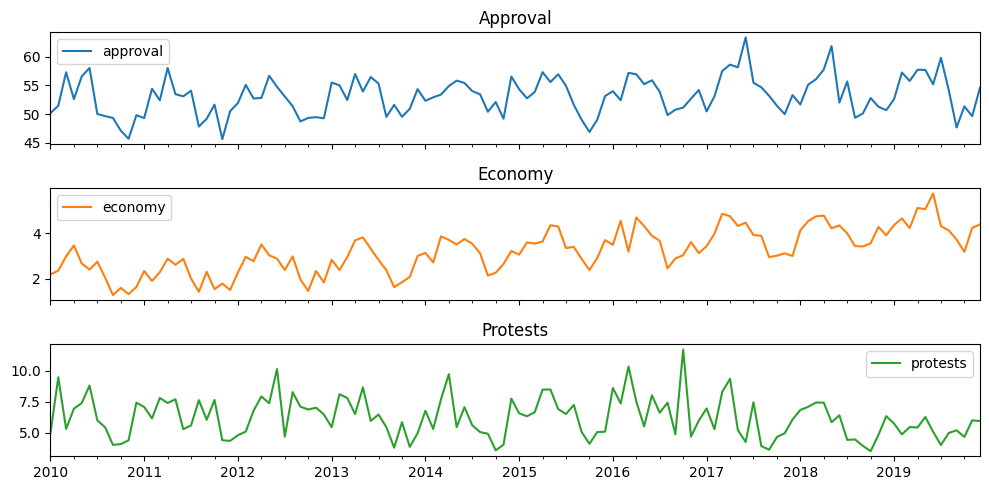

In [3]:
# plot
print('\nPlotting the series...')

# We plot each time series (approval, economy, protests) separately to observe their overall patterns.
# This helps students visually identify possible trends, seasonality, and volatility changes before any formal tests.
# The 'subplots=True' argument creates one subplot per variable, making it easier to compare them side by side.
ax = df.plot(subplots=True, layout=(3,1), linewidth=1.5, title=['Approval', 'Economy', 'Protests'])
plt.tight_layout()
plt.show()

# 3. Seasonality checks

Seasonality means a regular repeating pattern in the data (e.g., approval rising every election year or every winter month).

Detecting seasonality helps us decide if we need seasonal adjustments or dummy variables in our models.


Seasonal decomposition (STL) on approval:


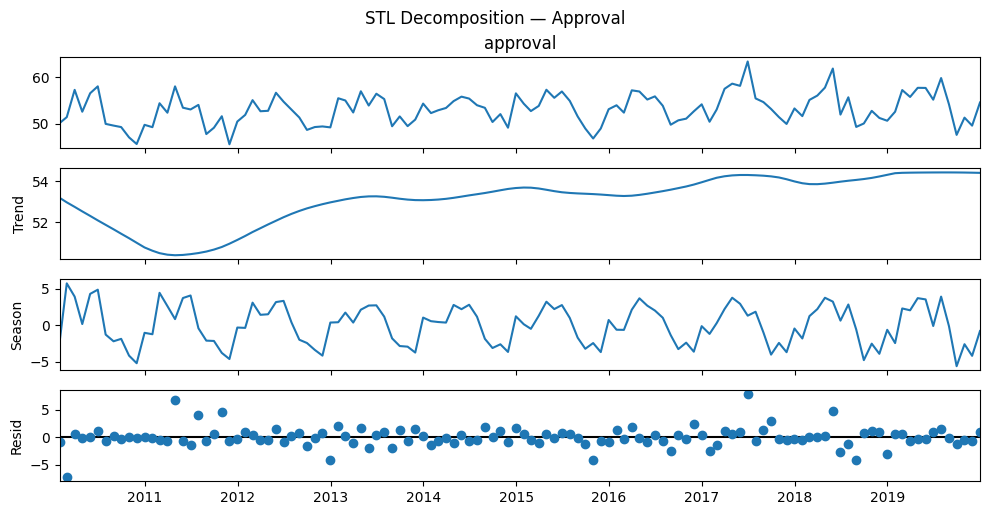

In [4]:
# 3.1 Visual seasonal decomposition (STL) for 'approval'
print('\nSeasonal decomposition (STL) on approval:')


# STL (Seasonal-Trend decomposition using Loess) separates a time series into three parts:
# - trend: long-term movement
# - seasonal: repeating cycles (monthly, quarterly, etc.)
# - residual: remaining irregular noise
# 'period=12' assumes a 12-month seasonal pattern (good for monthly data)
# 'robust=True' makes it less sensitive to outliers.
stl = STL(df['approval'], period=12, robust=True)
res = stl.fit()


# Plot the decomposition to visually see the separate components.
# Students should look for clear repeating waves in the 'seasonal' component, and a smoother long-term curve in the 'trend'.
res.plot(); plt.suptitle('STL Decomposition — Approval', y=1.02)
plt.show()


Average monthly pattern (approval):
1     52.230864
2     53.962647
3     54.879289
4     56.389467
5     56.518728
6     56.135201
7     54.637964
8     51.138490
9     49.988706
10    50.325249
11    49.340971
12    52.640277
Name: approval, dtype: float64


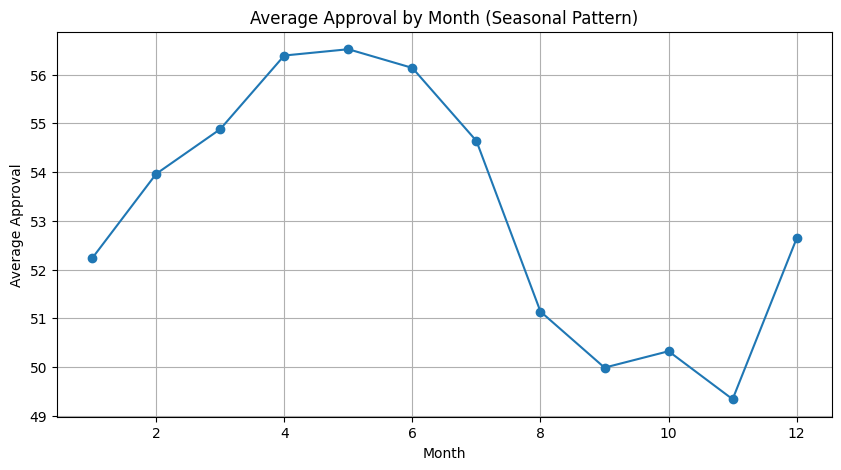

In [5]:
# 3.2 Check for monthly seasonality by grouping
print('\nAverage monthly pattern (approval):')

# Here we manually check for seasonality by computing the average approval rating for each month (Jan–Dec).
# If some months have systematically higher or lower averages, that’s evidence of seasonality.
monthly_means = df['approval'].groupby(df.index.month).mean()
print(monthly_means)

# Visualize the monthly averages to see if approval tends to peak or dip in specific months.
# This is often seen in survey data where public sentiment shifts around election cycles, holidays, or annual events.
monthly_means.plot(marker='o', linestyle='-');
plt.title('Average Approval by Month (Seasonal Pattern)')
plt.xlabel('Month')
plt.ylabel('Average Approval')
plt.grid(True)
plt.show()

# 4. Stationarity checks (ADF test)

Before applying VAR or Granger causality tests, the time series should be *stationary*.

A stationary series has constant mean, variance, and autocovariance over time.

Non-stationary data (e.g., with trends) can produce spurious correlations — an important issue for political science time series.

In [6]:
# We’ll use the Augmented Dickey-Fuller (ADF) test to check for stationarity.
# H0 (null hypothesis): the series has a unit root (non-stationary)
# H1 (alternative): the series is stationary.
# So: small p-value (< 0.05) → reject H0 → the series IS stationary.

def adf_test(series, name='series'):
  """
  Perform Augmented Dickey-Fuller test and print detailed results.
  Parameters:
  - series: time series to test (pandas Series)
  - name: name of the variable (string)
  """
  print(f"\nADF test for {name}:")


  # Run test with automatic lag length chosen by AIC criterion
  result = adfuller(series.dropna(), autolag='AIC')


  # Organize results for clarity
  labels = ['ADF Statistic','p-value','# lags used','Number of Observations Used']
  out = pd.Series(result[0:4], index=labels)


  # Add critical values for 1%, 5%, and 10% significance levels
  for key, value in result[4].items():
    out[f'crit_value_{key}'] = value

  print(out)
  # Interpretation guidance for students
  if out['p-value'] < 0.05:
    print(f"→ {name} appears STATIONARY (reject null of unit root).\n")
  else:
    print(f"→ {name} appears NON-STATIONARY (cannot reject null). Consider differencing.\n")

In [7]:
# Run the ADF test on the original series
# These tests check if each series (approval, economy, protests) is stationary in levels.
# Non-stationarity is common in social and political data — e.g., approval ratings drifting with long-term trends.
adf_test(df['approval'], 'approval')
adf_test(df['economy'], 'economy')
adf_test(df['protests'], 'protests')


ADF test for approval:
ADF Statistic                   -1.429983
p-value                          0.567820
# lags used                     12.000000
Number of Observations Used    107.000000
crit_value_1%                   -3.492996
crit_value_5%                   -2.888955
crit_value_10%                  -2.581393
dtype: float64
→ approval appears NON-STATIONARY (cannot reject null). Consider differencing.


ADF test for economy:
ADF Statistic                    0.615398
p-value                          0.987989
# lags used                     13.000000
Number of Observations Used    106.000000
crit_value_1%                   -3.493602
crit_value_5%                   -2.889217
crit_value_10%                  -2.581533
dtype: float64
→ economy appears NON-STATIONARY (cannot reject null). Consider differencing.


ADF test for protests:
ADF Statistic                   -5.271878
p-value                          0.000006
# lags used                      3.000000
Number of Observations Use

/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length

In [8]:
# If not stationary, difference the data
# Taking the first difference removes slow-moving trends and can induce stationarity.
print('\nIf series are non-stationary, take first differences and retest:')

df_diff = df.diff().dropna()

# Run the same ADF test again on the differenced data.
# The goal is to achieve stationarity — now changes (ΔX_t) instead of levels (X_t) should fluctuate around a constant mean.
adf_test(df_diff['approval'], 'approval (1st diff)')
adf_test(df_diff['economy'], 'economy (1st diff)')
adf_test(df_diff['protests'], 'protests (1st diff)')


If series are non-stationary, take first differences and retest:

ADF test for approval (1st diff):
ADF Statistic                 -7.779214e+00
p-value                        8.505937e-12
# lags used                    1.100000e+01
Number of Observations Used    1.070000e+02
crit_value_1%                 -3.492996e+00
crit_value_5%                 -2.888955e+00
crit_value_10%                -2.581393e+00
dtype: float64
→ approval (1st diff) appears STATIONARY (reject null of unit root).


ADF test for economy (1st diff):
ADF Statistic                 -7.690246e+00
p-value                        1.425595e-11
# lags used                    1.200000e+01
Number of Observations Used    1.060000e+02
crit_value_1%                 -3.493602e+00
crit_value_5%                 -2.889217e+00
crit_value_10%                -2.581533e+00
dtype: float64
→ economy (1st diff) appears STATIONARY (reject null of unit root).


ADF test for protests (1st diff):
ADF Statistic                 -6.554913e+00
p

/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
/tmp/ipykernel_1165/3642159411.py:17: FutureWarning: adfuller currently returns a plain tuple whose length

# 5. Prepare data for VAR (Vector Autoregression)

At this stage, we want to model how multiple time series influence each other dynamically.

The VAR model allows each variable to depend on its own lags and on the lags of the other variables.

Example for our context: approval_t may depend on past approval, past economy, and past protests.

In [9]:
# Before fitting VAR, **all series must be stationary**.
# Based on ADF results from step 4, we’ll use the differenced data (df_diff).

print('\nPreparing stationary data for the VAR model...')

# Create a new dataframe for modeling.
model_data = df_diff.copy()


# Always inspect the first few rows to ensure no NaN values remain.
print('\nFirst 5 rows of differenced data used for VAR:')
print(model_data.head())


Preparing stationary data for the VAR model...

First 5 rows of differenced data used for VAR:
            approval   economy  protests
2010-02-28  1.274670  0.167017  4.472533
2010-03-31  5.864457  0.628210 -4.147215
2010-04-30 -4.696396  0.478325  1.630409
2010-05-31  3.966556 -0.789045  0.442575
2010-06-30  1.486289 -0.271805  1.412141


In [10]:
# Conceptual explanation
# - Differencing converts each series into changes from one period to the next (ΔX_t = X_t - X_{t-1}).
# - This removes long-term trends and focuses the model on short-term dynamics.
# - VAR is useful when variables are potentially interdependent — like political approval reacting to economic shifts, and vice versa.
# - In political science, this approach helps uncover feedback loops (e.g., low approval → more protests → further decline in approval).

# 6. Granger Causality Tests

Once we have stationary data, we can explore predictive relationships between variables.

The Granger causality test examines whether past values of one time series help predict another.

In political science, this can be used to test hypotheses like:
- Does economic performance predict (Granger-cause) government approval ratings?
- Does approval predict protest activity?


**IMPORTANT:** Granger causality ≠ true causality. It only means one variable has predictive content for another.

In [25]:
# Define the maximum number of lags to test.
# Since our data is monthly, we can use up to 6 months (half a year) of lags.
maxlag = 6

# The function grangercausalitytests() expects the columns ordered as [dependent, predictor].
# Here, we test if lagged values of 'economy' improve prediction of 'approval'.
gc1 = grangercausalitytests(model_data[['approval', 'economy']], maxlag=maxlag)

# Pull out the F-test p-value for each lag
for lag in range(1, maxlag + 1):
    f_stat, p_val, _, _ = gc1[lag][0]['ssr_ftest']
    print(f"lag {lag}: F = {f_stat:.3f}, p = {p_val:.4f}")


#The null hypothesis is rejected at every lag from 1 to 6.
#Lagged values of economy improve the prediction of approval beyond what approval’s own lags provide.
#The p-values print as 0.0000, which means they are below 0.00005, so they are effectively zero at this precision.


lag 1: F = 18.422, p = 0.0000
lag 2: F = 19.132, p = 0.0000
lag 3: F = 13.589, p = 0.0000
lag 4: F = 10.227, p = 0.0000
lag 5: F = 8.958, p = 0.0000
lag 6: F = 6.231, p = 0.0000


In [27]:
# Now test if past approval helps predict protest activity.
gc2 = grangercausalitytests(model_data[['protests', 'approval']], maxlag=maxlag)

for lag in range(1, maxlag + 1):
    f_stat, p_val, _, _ = gc2[lag][0]['ssr_ftest']
    print(f"lag {lag}: F = {f_stat:.3f}, p = {p_val:.4f}")

#The null is rejected at every lag, including at a Bonferroni-adjusted threshold of 0.05/6 = 0.0083,
#so the result doesn’t depend on picking a convenient lag.
#Past approval improves the prediction of protests beyond protests’ own history.

lag 1: F = 13.293, p = 0.0004
lag 2: F = 7.573, p = 0.0008
lag 3: F = 5.439, p = 0.0016
lag 4: F = 4.335, p = 0.0028
lag 5: F = 4.902, p = 0.0005
lag 6: F = 4.734, p = 0.0003


In [28]:
# How to interpret results
# - For each lag (1 to 6), the output shows several test statistics.
# - The most common is 'ssr_ftest' with its F-statistic and p-value.
# - Small p-values (< 0.05) → reject the null hypothesis → evidence of Granger causality.
# - For example: if p < 0.05 in the economy→approval test, we conclude that economic conditions help predict approval.

In [29]:
print('\nInterpretation tip: look for small p-values (under 0.05) in the ssr_ftest column — these indicate predictive relationships.')


Interpretation tip: look for small p-values (under 0.05) in the ssr_ftest column — these indicate predictive relationships.


# 7. Build a VAR (Vector Autoregression) Model

After testing for Granger causality, we can estimate a full VAR model.

VAR allows us to model the joint dynamics of multiple stationary series simultaneously.

Each variable is explained by its own past values and the past values of the other variables.

In [30]:
# === 7.1 Lag Order Selection ===
# Choosing the correct lag length is crucial: too few lags → miss dynamics; too many → overfit and lose degrees of freedom.
# The VAR class includes automatic lag selection based on AIC, BIC, HQIC, etc.

model = VAR(model_data)
lag_order_results = model.select_order(maxlags=12)
print('\nLag order selection criteria (AIC, BIC, etc.):')
print(lag_order_results.summary())

# Choose the lag that minimizes the AIC criterion (common practice)
chosen_lag = lag_order_results.aic
print(f"\nChosen lag order by AIC: {chosen_lag}")

# If AIC doesn’t return a number (can happen occasionally), use a default small lag (like 2).
if chosen_lag is None:
  selected_lag = 2
else:
  selected_lag = int(chosen_lag)


Lag order selection criteria (AIC, BIC, etc.):
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        2.685       2.760       14.66       2.716
1        1.796      2.096*       6.025       1.917
2        1.580       2.104       4.857      1.792*
3        1.647       2.396       5.200       1.951
4        1.565       2.539       4.799       1.960
5        1.555       2.754       4.768       2.041
6        1.576       3.000       4.890       2.153
7        1.495       3.144       4.542       2.164
8        1.498       3.372       4.594       2.258
9        1.408       3.506       4.241       2.258
10      1.259*       3.582      3.708*       2.201
11       1.352       3.900       4.139       2.385
12       1.319       4.091       4.087       2.443
--------------------------------------------------

Chosen lag order by AIC: 10


In [31]:
# === 7.2 Fit the VAR Model ===
print(f"\nFitting VAR with {selected_lag} lags on differenced (stationary) data...")
var_res = model.fit(selected_lag)
print(var_res.summary())


Fitting VAR with 10 lags on differenced (stationary) data...
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Thu, 19, Nov, 2026
Time:                     12:47:21
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    3.49686
Nobs:                     109.000    HQIC:                   2.13180
Log likelihood:          -436.424    FPE:                    3.48670
AIC:                      1.20058    Det(Omega_mle):         1.64554
--------------------------------------------------------------------
Results for equation approval
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const                0.038246         0.236110            0.162           0.871
L1.approval         -0.909056         0.110363           -8.237           0.000

In [32]:
# Interpretation
# - Coefficients show how each variable responds to its own and others’ past changes.
# - Look for significant coefficients (p < 0.05) — e.g., if ΔEconomy_{t-1} predicts ΔApproval_t.
# - Remember: coefficients are for *changes*, since we used differenced data.

In [33]:
# 7.3 Model Stability
# A stable VAR has all roots inside the unit circle (<1). This ensures the system won’t explode over time.
print('\nChecking model stability (all roots should be < 1):')
print(var_res.is_stable())


Checking model stability (all roots should be < 1):
True


In [34]:
# 7.4 Diagnostic Check: Serial Correlation in Residuals
# We test whether residuals are uncorrelated (white noise).
# If they’re autocorrelated, the model might miss some dynamics.
print('\nLjung-Box test for serial correlation in residuals (12 lags):')
for col in model_data.columns:
  lb = acorr_ljungbox(var_res.resid[col], lags=[12], return_df=True)
  print(f"Residual Ljung-Box test for {col}:")
  print(lb)


Ljung-Box test for serial correlation in residuals (12 lags):
Residual Ljung-Box test for approval:
    lb_stat  lb_pvalue
12  6.37545   0.895986
Residual Ljung-Box test for economy:
      lb_stat  lb_pvalue
12  11.802462   0.461672
Residual Ljung-Box test for protests:
      lb_stat  lb_pvalue
12  11.512981   0.485541


# 8. Impulse Response Functions (IRF)

After estimating a stable VAR, we can explore how a shock (unexpected change) in one variable affects others over time.

This is done using Impulse Response Functions (IRFs).

Example: what happens to approval over the next year if the economy suddenly improves?

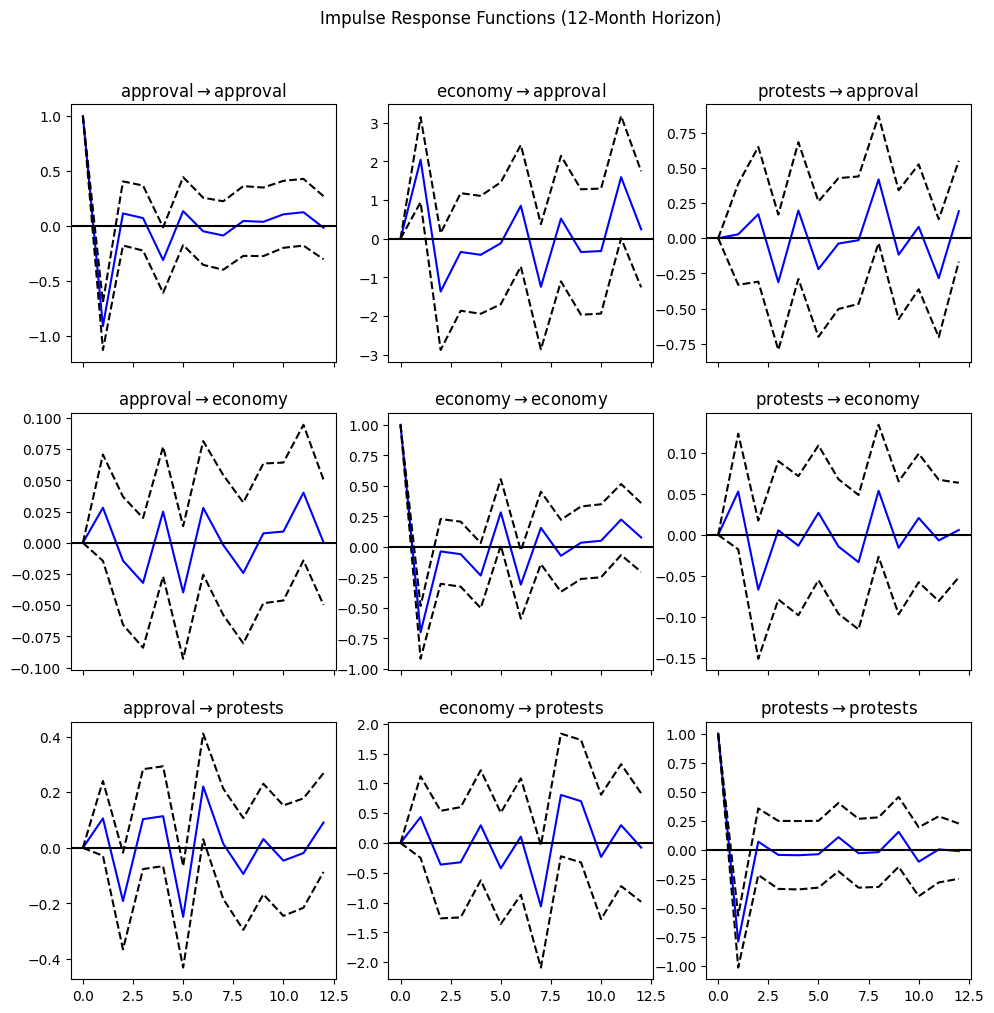

In [35]:
# Compute the impulse responses up to 12 periods (months) ahead.
irf = var_res.irf(12)

# Plot the IRFs — these show how each variable responds to a one-time shock in any other variable.
# By default, shocks are one standard deviation in size.
irf.plot(orth=False)
plt.suptitle('Impulse Response Functions (12-Month Horizon)', y=1.02)
plt.show()

In [36]:
# Interpretation guidance
# - Each panel shows how one variable (row) responds to a shock in another variable (column).
# - For example, the plot of Approval → Economy shows how economic shocks affect approval over time.
# - Positive or negative responses over time indicate the direction and persistence of the effect.
# - Confidence bands help judge statistical significance (zero line = no effect).

# 9. Forecasting with VAR
Another application of VARs is forecasting future values given past patterns.

In [37]:
# Define the number of periods to forecast.
n_forecast = 12

# Retrieve the lag order from the fitted model.
lag_order = var_res.k_ar
print(f"\nUsing lag order = {lag_order} for forecasting.")

# Prepare input data: last 'lag_order' observations.
forecast_input = model_data.values[-lag_order:]


Using lag order = 10 for forecasting.


In [38]:
# Generate forecasts (still in differenced form).
fc = var_res.forecast(y=forecast_input, steps=n_forecast)

# Create forecast index (monthly)
fc_index = pd.date_range(start=model_data.index[-1] + pd.offsets.MonthEnd(1), periods=n_forecast, freq='M')
fc_df = pd.DataFrame(fc, index=fc_index, columns=model_data.columns)
print('\nForecasted (differenced) values — first few rows:')
print(fc_df.head())

# Convert from differences back to levels by cumulative sum, starting from the last observed actual level.
last_levels = df.iloc[-1]
fc_levels = fc_df.cumsum().add(last_levels)
print('\nForecasted (levels) values — first few rows:')
print(fc_levels.head())


Forecasted (differenced) values — first few rows:
            approval   economy  protests
2020-01-31  1.882861  0.438014 -1.190353
2020-02-29 -0.718021  0.103718  2.375557
2020-03-31  0.142345  0.056880 -0.510850
2020-04-30  0.386463  0.195862  0.240679
2020-05-31  2.475096  0.227325 -0.028223

Forecasted (levels) values — first few rows:
             approval   economy  protests
2020-01-31  56.482368  4.838788  4.749697
2020-02-29  55.764348  4.942505  7.125254
2020-03-31  55.906693  4.999385  6.614404
2020-04-30  56.293155  5.195246  6.855083
2020-05-31  58.768252  5.422572  6.826859


/tmp/ipykernel_1165/4251620487.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  fc_index = pd.date_range(start=model_data.index[-1] + pd.offsets.MonthEnd(1), periods=n_forecast, freq='M')


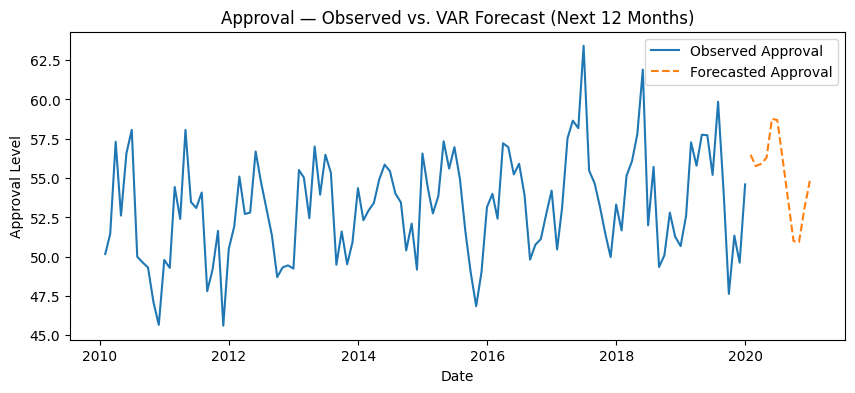

In [39]:
# Plot observed and forecasted approval to visualize predicted trends.
plt.figure(figsize=(10,4))
plt.plot(df['approval'], label='Observed Approval')
plt.plot(fc_levels['approval'], label='Forecasted Approval', linestyle='--')
plt.legend()
plt.title('Approval — Observed vs. VAR Forecast (Next 12 Months)')
plt.xlabel('Date')
plt.ylabel('Approval Level')
plt.show()